# INF201 - Deliverable 2
## Campus Coffee Shop Sales Pipeline

**Group:** G6_2: Nikolai Friis, Tommy Rustad Apelseth, Aron Lerdahl 

**GitHub repository:** https://github.com/tommyra06/INF201-Deliverables 

---

### Contents
* Setup
* Task 1: File ingestion and regular expressions
* Task 2: Recursive utility functions
* Task 3: Cleaning and analysing data using NumPy
* Task 4: Data analysis using Pandas
* Task 5: Full workflow
* Use of generative AI

---

## Setup

### Virtual environment

A new virtual environment (`.venv`) was created for Deliverable 2, and the packages used are listed within `requirements.txt`. To recreate the environment: 

```bash
python -m venv .venv
pip install -r requirements.txt
```
### Input data 
The input data is generated by running the `generate_data_for_d2.py` which is in `Oppgavefiler/` from the project folder. `BASE_DIR` in the script is set to `Path("d2_data")`, so the data is saved in the `d2_data/` folder next to this notebook. The script creates these: 

* `d2_data/2026/<store>/<register>/register_sales.log` - log files in mixed encodings (UTF-8 and ISO-8859-1 (Latin-1))
* `d2_data/store_config.json` - nested store and register metadata

The `d2_data/` folder is not uploaded to GitHub, so the script must be run before running this notebook.

### Imports and file paths
All imports used in the notebook are collected in the cell below, together with the paths to the input data and the output folder.

In [1]:
# Library imports that come with Python
import json  # Reads store_config.json (Task 2) as well as save hourly_revenue.json (Task 5)
import pathlib  # File and folder paths: Reading files (Task 1) and search (Task 2)
import re  # Used for regular expressions to parse valid sales lines in the logs (Task 1)

# Installed libraries, listed in `requirements.txt`
import chardet as cd  # Detects encoding (Task 1)
import matplotlib.pyplot as plt  # Plotting results (Task 5)
import numpy as np  # Array calculations, such as outlier cleaning and refund ratios (Task 3)
import pandas as pd  # DataFrames, resampling, pivot tables, and saving CSV files (Task 4 and Task 5)

# Paths to the input data
DATA_DIR: pathlib.Path = pathlib.Path("d2_data")                    # Folder with the generated log files and config (Task 2 and 5)
CONFIG_FILE: pathlib.Path = DATA_DIR / "store_config.json"  # Nested store and register metadata (Task 2 and 5)

# Path to the output files
OUTPUT_DIR: pathlib.Path = pathlib.Path("output")  # Folder where the output files are saved (Task 5)


---

## Task 1: File ingestion and regular expressions

For Task 1, we are writing two functions

1. `file_reader` - Uses chardet to identify the encoding, then stores file content as string.
2. `log_parser` - Stores file content through `file_reader`, and matches each line with a preset pattern.





---

## 1.1 File reading

The function takes a file path and converts it to a `pathlib.Path` object. It first reads the file in binary mode `('rb')` so that the encoding can be detected using `chardet.detect()`.

The detected encoding is then used to reopen the file in read mode:

* `readlines()` reads the file into a list of lines.
* Each line is added to the info string.

Finally, the function returns a tuple containing the file content as a string and the detected encoding.

In [2]:

def file_reader(path: str | pathlib.Path) -> tuple[str, str]:
    '''
    Detects file encoding and returns content as string.

    Parameters
    ----------
    path : str | pathlib.Path
        Directory to file. Converted to a pathlib.Path object.

    Returns
    -------
    tuple[str,str]
        First string is file content.
        Second string is file encoding
    '''
    file_dir = pathlib.Path(path)
    info = ''

    with open(file_dir, 'rb') as file:
        raw = file.read()

    result = cd.detect(raw)
    encoding = result['encoding']

    with open(file_dir, 'r', encoding=encoding) as f:
            data = f.readlines()
            for line in data:
                info += line
    return(info, encoding)  

---

## 1.2 Line matching

The function takes a file path and uses `file_reader()` to read the contents. It creates a regular expression with named capture groups to extract the timestamp, register ID, item, price, currency and transaction status.

The file contents are split into individual lines, and the function loops through each line:

* If the line matches the pattern, the extracted values are stored in a dictionary using `match.groupdict()`.
* The price is converted from a string to a float.
* The dictionary is added to the info list.
* Lines that do not match are ignored.

Finally, the function returns the list of dictionaries, where each dictionary represents one valid log entry.



In [3]:

def log_parser(path: str) -> list[dict]:
    '''
    Recursively matches each line in file to pattern.

    Parameters
    ----------
        Directory to file
    
    Returns
    -------
        List of dictionaries for each line in the file.
    '''
    info = []
    pattern = re.compile(
            r"\[(?P<timestamp>\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2})\]\s+"
            r"\[(?P<register_id>[^\]]+)\]\s+"
            r"item=(?P<item>\S+)\s+"
            r"price=(?P<price>\d+\.\d+)\s+"
            r"(?P<currency>[A-Z]{3})\s+"
            r"\((?P<status>SUCCESS|REFUND|CANCELLED)\)"
        )
    data = file_reader(path)[0]
    data = data.split('\n')
    for line in data:
        match = pattern.match(line)
        if match:
            data = match.groupdict()
            data['price'] = float(data['price'])
            info.append(data)
    return(info)


---

## Task 2: Recursive utility functions

For Task 2, we are writing two recursive helper functions that are used in the full workflow in Task 5.

1. `find_log_files` - searches through the nested `d2_data/` folder structure (year → store → register) and returns all `.log` files.
2. `find_active_registers` - traverses the nested `store_config.json` file and returns the IDs of all registers marked as active.

Both functions use explicit recursion: each call handles one level of the structure and calls itself on the levels below. As required, we do not use `Path.glob()`, `Path.rglob()` or `os.walk()`.

---

### 2.1 Recursive search for log files

The function takes a folder path and converts it to a `pathlib.Path` object. It then loops over everything directly inside the folder using `Path.iterdir()`:

* If the item is a **folder**, the function calls itself on that folder and adds the files it ends up finding to the list (this is the recursive step).
* If the item is a **file** with the right extension, it is added to the list.
* Other files (e.g. `store_config.json`) are ignored.

The recursion stops when a folder only contains files, since no new calls are made, which is the base case. The list is sorted and returned, so the order of files is the same every time the code runs.

The input path has the type hint `str | Path`, since the function accepts both a string and a `Path` object.

In [4]:
def find_log_files(path: str | pathlib.Path, extension: str = ".log") -> list[pathlib.Path]:
    """
    Recursively find all files with a given extension in a directory tree.    
    
    Parameters                                                               
    ----------
    path : str | Path
        The directory to search in. Converted to a pathlib.Path object.
    extension : str, optional
        The file extension to search for, including the dot (default ".log").
        
    Returns                                                                       
    -------
    list[Path]
        Sorted list of Path objects for all matching files in the directory 
        and all of its subdirectories.
    """
    path = pathlib.Path(path)
    found: list[pathlib.Path] = []

    for item in path.iterdir():
        if item.is_dir():
            # Recursive step: Search inside the subdirectory 
            found.extend(find_log_files(item, extension))
        elif item.is_file() and item.suffix == extension: 
            found.append(item)

    return sorted(found) 

---

### 2.2 Recursive search for active registers

The configuration file contains dictionaries and lists nested inside each other. Since we don't want the function to depend on the exact structure, it handles any combination of the two:

* If the input is a **dictionary**, we check whether it has `"active": True` and an `"id"`. If so, the id is added to the set. The function then calls itself on every value in the dictionary.
* If the input is a **list**, the function calls itself on every element.
* Anything else (strings, numbers, booleans, `None`) returns an empty set. This is the base case.

The results from each recursive call are combined using set union (`|=`). We return a `set[str]` so the same register id is never stored twice. Note that `true` in JSON becomes `True` in Python when the file is loaded with `json.load`.

To give the input a precise type hint, we define the type alias `JSONValue`, which describes every type a value loaded from a JSON file can have. The alias refers to itself, since a dictionary or list can contain more dictionaries and lists.

In [5]:
JSONValue = dict[str, "JSONValue"] | list["JSONValue"] | str | int | float | bool | None


def find_active_registers(node: JSONValue) -> set[str]:
    """
    Recursively collect the ids of all active registers in a nested JSON structure.

    Parameters
    ----------
    node : JSONValue
        Any part of the loaded JSON data: a dictionary, a list or a single value.

    Returns
    -------
    set[str]
        The ids of all registers where "active" is True. Returns an empty set
        if node is not a dictionary or a list (the base case).
    """
    active: set[str] = set()

    if isinstance(node, dict):
        if node.get("active") is True and "id" in node:
            active.add(str(node["id"]))
        # Recursive step: search every value in the dictionary
        for value in node.values():
            active |= find_active_registers(value)

    elif isinstance(node, list):
        # Recursive step: search every element in the list
        for element in node:
            active |= find_active_registers(element)

    return active

---

### Testing each function 

We test both functions on the data generated by `generate_data_for_d2.py`.

In [6]:
log_files: list[pathlib.Path] = find_log_files(DATA_DIR)
print(f"Found {len(log_files)} log files:")
for file in log_files:
    print(" ", file)

with open(CONFIG_FILE, encoding="utf-8") as f:
    config: JSONValue = json.load(f)

active_registers: set[str] = find_active_registers(config)
print("\nActive registers:", sorted(active_registers))

Found 9 log files:
  d2_data/2026/library_cafe/POS_01/register_sales.log
  d2_data/2026/library_cafe/POS_02/register_sales.log
  d2_data/2026/library_cafe/POS_03/register_sales.log
  d2_data/2026/science_building/POS_01/register_sales.log
  d2_data/2026/science_building/POS_02/register_sales.log
  d2_data/2026/science_building/POS_03/register_sales.log
  d2_data/2026/student_union/POS_01/register_sales.log
  d2_data/2026/student_union/POS_02/register_sales.log
  d2_data/2026/student_union/POS_03/register_sales.log

Active registers: ['POS_01', 'POS_02', 'POS_03']


---

### Results and discussion of Task 2

`find_log_files` found all 9 log files, one for each register (`POS_01`-`POS_03`) in each of the three stores.

`find_active_registers` returned `{'POS_01', 'POS_02', 'POS_03'}`. `POS_04` is not included since it is marked as `"active": false` in the config.

One thing to note is that the config file only lists register ids, not which store each register belongs to. All registers that appear in the log files are active, so filtering the transactions by active register in Task 5 will **not** remove any rows with this dataset.

---

## Task 3: Cleaning and analysing data using NumPy

For Task 3, we are writing two NumPy functions that are used in the full workflow in Task 5.

1. `remove_outliers` - finds hardware glitch prices (such as `999.00`) and replaces them with the median of the valid prices.
2. `compute_refund_ratio` - calculates the refund ratio for each item from the number of sales and refunds.

Both functions work on whole NumPy arrays at once (vectorised operations), instead of looping over each value in Python.

---

### 3.1 Removing price outliers

The function takes the price data and converts it to a 1D NumPy float array, so it accepts a list, a NumPy array or a pandas column. It then:

* Calculates the mean ($\mu$) and the standard deviation ($\sigma$) of all the prices.
* Marks a price as an outlier if it deviates from the mean by more than three standard deviations: $\lvert x - \mu \rvert > 3\sigma$. This gives a boolean mask that is `True` for every outlier.
* Calculates the median of the valid prices (the ones that are not outliers) and puts it in place of each outlier.

The function works on a copy, so the original input is not changed.

In [7]:
def remove_outliers(prices: list[float] | np.ndarray | pd.Series) -> np.ndarray:
    """
    Remove outliers from a list of prices using the formula described. (|x - mu| > 3 * sigma)

    Parameters
    ----------
    prices : list[float] | np.ndarray | pd.Series
        A list, NumPy array, or Pandas series of price values.

    Returns
    -------
    np.ndarray
        An array with outliers replaced by the median.
    """
    arr = np.array(prices, dtype=float).flatten()
    
    mu = arr.mean()
    sigma = arr.std()

    outliers = np.abs(arr - mu) > 3 * sigma

    median = np.median(arr[~outliers])
    arr[outliers] = median

    return arr


---

### 3.2 Computing refund ratios

The function `compute_refund_ratio(sales_count: np.ndarray, refund_count: np.ndarray) -> np.ndarray` takes two arrays of the same length: the number of sales and the number of refunds for each item. The ratio is calculated element-wise:

$$\text{Refund Ratio} = \frac{\text{Refund Count}}{\text{Sales Count} + 10^{-6}}$$

* NumPy divides the arrays element by element, so the first refund count is divided by the first sales count, and so on. No loop is needed.
* The small number $\epsilon = 10^{-6}$ is added to the sales count so we never divide by zero, for example if an item has no sales. It is too small to noticeably change the ratio for items that do have sales.

The function returns an array of ratios in the same order as the input arrays. It is used in Task 4, where the counts are taken from the DataFrame.

In [8]:
def compute_refund_ratio(sales_count: np.ndarray, refund_count: np.ndarray) -> np.ndarray:
    """
    Compute the refund ratio for each product.

    Parameters
    ----------
    sales_count : np.ndarray
        An array of sales counts for each product.
    refund_count : np.ndarray
        An array of refund counts for each product.

    Returns
    -------
    np.ndarray
        An array of refund ratios for each product.
    """

    refund_ratio = refund_count / (sales_count + 1e-6)

    return refund_ratio


---

### Testing each function

We test both functions on small example arrays where the correct result is easy to check by hand.

In [9]:
# Test remove_outliers: 12 normal prices and one glitch (999.0)
test_prices: list[float] = [4.5, 3.0, 5.0, 4.0, 3.5, 4.5, 5.5, 3.0, 4.0, 4.5, 5.0, 3.5, 999.0]
cleaned: np.ndarray = remove_outliers(test_prices)

print("Original prices:", test_prices)
print("Cleaned prices: ", cleaned)

# Test compute_refund_ratio: the last item has no sales, so epsilon prevents division by zero
sales: np.ndarray = np.array([10, 4, 0])
refunds: np.ndarray = np.array([2, 1, 0])
ratios: np.ndarray = compute_refund_ratio(sales, refunds)

print("\nRefund ratios:", np.round(ratios, 4))

# Edge case: refunds but no sales gives a very large ratio
print("0 sales, 1 refund:", compute_refund_ratio(np.array([0]), np.array([1])))

Original prices: [4.5, 3.0, 5.0, 4.0, 3.5, 4.5, 5.5, 3.0, 4.0, 4.5, 5.0, 3.5, 999.0]
Cleaned prices:  [4.5  3.   5.   4.   3.5  4.5  5.5  3.   4.   4.5  5.   3.5  4.25]

Refund ratios: [0.2  0.25 0.  ]
0 sales, 1 refund: [1000000.]


---

### Results and discussion of Task 3

`remove_outliers` replaced the glitch price `999.0` with `4.25`, which is the median of the 12 valid prices. The other prices kept their values and positions, and the original list was not changed, since the function works on a copy.

`compute_refund_ratio` returned `[0.2, 0.25, 0.0]` for the three test items. Because of $\epsilon$, the unrounded values are very slightly smaller than the exact ratios (for example `0.19999998` instead of `0.2`), which makes no practical difference.

---

## Task 4: Data analysis using Pandas

For Task 4, we are writing four Pandas functions that are used in the full workflow in Task 5.

1. `build_dataframe` - converts the list of transaction dictionaries from Task 1 into a DataFrame, with the timestamp as a sorted `datetime` index.
2. `hourly_revenue` - groups the transactions by item and sums the price in 1-hour windows.
3. `status_pivot` - creates a pivot table with the total revenue for each item across the status categories `SUCCESS`, `REFUND` and `CANCELLED`.
4. `refund_ratios` - counts the sales and refunds for each item and calculates the refund ratio using `compute_refund_ratio` from Task 3.

The last three functions all take the DataFrame from `build_dataframe` as input, so they can be called one after another in Task 5.

---

### 4.1 Building the DataFrame

The function takes the list of dictionaries returned by the log parser in Task 1, where each dictionary is one transaction. It then:

* Creates a `pandas.DataFrame`, where each dictionary becomes a row and each key becomes a column.
* Converts the `timestamp` column from text to `datetime` using `pd.to_datetime()`.
* Sets `timestamp` as the index of the DataFrame and sorts the rows chronologically.

A sorted `datetime` index is what makes it possible to resample the transactions by time in Task 4.2.

In [10]:
def build_dataframe(transactions: list[dict[str, str | float]]) -> pd.DataFrame:
    """
    Convert the list of transactions into a DataFrame sorted by time.

    Parameters
    ----------
    transactions : list[dict[str, str | float]]
        The transaction dictionaries from the log parser in Task 1, one per
        valid log line.

    Returns
    -------
    pd.DataFrame
        One row per transaction, with the timestamp as a sorted datetime
        index and price as a float.
    """
    
    df = pd.DataFrame(transactions)
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    
    # Converting to float just in case
    df["price"] = df["price"].astype(float)
    
    df = df.set_index("timestamp").sort_index()
    
    return df

---

### 4.2 Hourly revenue per item

The function groups the transactions by `item`, and then resamples each group into 1-hour windows (`"1h"`), summing the `price` column within each window. The result has one total for each combination of item and hour.

We sum the price of all transactions, regardless of status. This follows the assignment, which also counts `REFUND` and `CANCELLED` transactions as "transaction revenue" in Task 4.3.

In [11]:
def hourly_revenue(df: pd.DataFrame) -> pd.DataFrame:
    """
    Calculate the total price for each item in 1-hour windows.

    Parameters
    ----------
    df : pd.DataFrame
        The DataFrame from build_dataframe, with a datetime index.

    Returns
    -------
    pd.DataFrame
        One row per item and hour, indexed by (item, timestamp), with the
        total price in the column price.
    """
    
    return df.groupby("item")["price"].resample("1h").sum().to_frame(name="price")

---

### 4.3 Pivot table of revenue by status

The function uses `pivot_table()` to create a table with one row per item and one column per status (`SUCCESS`, `REFUND` and `CANCELLED`). Each cell contains the total price of the transactions with that item and status.

If an item has no transactions with a given status, the cell is filled with `0` instead of being left empty (`NaN`).

In [12]:
def status_pivot(df: pd.DataFrame) -> pd.DataFrame:
    """
    Create a pivot table of the total price for each item and status.

    Parameters
    ----------
    df : pd.DataFrame
        The DataFrame from build_dataframe.

    Returns
    -------
    pd.DataFrame
        One row per item and one column per status (SUCCESS, REFUND,
        CANCELLED), containing the total price. Missing values are 0.
    """
    
    pivot = df.pivot_table(index="item", columns="status", values="price", aggfunc="sum", fill_value=0)

    # Returns with statuses in the correct order as columns
    return pivot.reindex(columns=["SUCCESS", "REFUND", "CANCELLED"], fill_value=0)

---

### 4.4 Refund ratio per item

The function counts the number of transactions for each combination of item and status using `pd.crosstab()`. It then:

* Uses the number of `SUCCESS` transactions as the sales count, and the number of `REFUND` transactions as the refund count.
* Converts both columns to NumPy arrays and passes them to `compute_refund_ratio` from Task 3.
* Returns a DataFrame with the item, sales count, refund count and refund ratio.

If a status never appears in the data, its column is added with zeros, so the function still works.

In [13]:
def refund_ratios(df: pd.DataFrame) -> pd.DataFrame:
    """
    Calculate the refund ratio for each item. The sales count is the number of SUCCESS transactions, and the refund
    count is the number of REFUND transactions.

    Parameters
    ----------
    df : pd.DataFrame
        The DataFrame from build_dataframe.

    Returns
    -------
    pd.DataFrame
        One row per item with the columns item, sales_count, refund_count
        and refund_ratio.
    """
    counts = pd.crosstab(df["item"], df["status"])
    # Add a status column with zeros if it never appears in the data
    counts = counts.reindex(columns=["SUCCESS", "REFUND"], fill_value=0)

    sales = counts["SUCCESS"].to_numpy()
    refunds = counts["REFUND"].to_numpy()

    return pd.DataFrame({
        "item": counts.index.to_numpy(),
        "sales_count": sales,
        "refund_count": refunds,
        "refund_ratio": compute_refund_ratio(sales, refunds),
    })

---

### Testing each function

We test all four functions on the transactions parsed from the log files generated by `generate_data_for_d2.py`.

In [14]:
# Small hand-made transactions in the same format as the Task 1 parser output.
# The rows are not in time order and the prices are text, to check that build_dataframe handles both.
test_transactions: list[dict[str, str | float]] = [
    {"timestamp": "2026-10-15 09:10:00", "register_id": "POS_01", "item": "Latte",  "price": "4.50", "currency": "EUR", "status": "SUCCESS"},
    {"timestamp": "2026-10-15 07:05:00", "register_id": "POS_01", "item": "Latte",  "price": "4.00", "currency": "EUR", "status": "SUCCESS"},
    {"timestamp": "2026-10-15 07:30:00", "register_id": "POS_02", "item": "Latte",  "price": "4.00", "currency": "EUR", "status": "REFUND"},
    {"timestamp": "2026-10-15 07:45:00", "register_id": "POS_02", "item": "Muffin", "price": "3.00", "currency": "NOK", "status": "SUCCESS"},
    {"timestamp": "2026-10-15 08:15:00", "register_id": "POS_03", "item": "Muffin", "price": "3.50", "currency": "USD", "status": "CANCELLED"},
]

df_test: pd.DataFrame = build_dataframe(test_transactions)
print("DataFrame:")
print(df_test)
print("\nPrice type:", df_test["price"].dtype, "| Sorted:", df_test.index.is_monotonic_increasing)

print("\nHourly revenue:")
print(hourly_revenue(df_test))

print("\nRevenue by status:")
print(status_pivot(df_test))

print("\nRefund ratios:")
print(refund_ratios(df_test).round(4))

DataFrame:
                    register_id    item  price currency     status
timestamp                                                         
2026-10-15 07:05:00      POS_01   Latte    4.0      EUR    SUCCESS
2026-10-15 07:30:00      POS_02   Latte    4.0      EUR     REFUND
2026-10-15 07:45:00      POS_02  Muffin    3.0      NOK    SUCCESS
2026-10-15 08:15:00      POS_03  Muffin    3.5      USD  CANCELLED
2026-10-15 09:10:00      POS_01   Latte    4.5      EUR    SUCCESS

Price type: float64 | Sorted: True

Hourly revenue:
                            price
item   timestamp                 
Latte  2026-10-15 07:00:00    8.0
       2026-10-15 08:00:00    0.0
       2026-10-15 09:00:00    4.5
Muffin 2026-10-15 07:00:00    3.0
       2026-10-15 08:00:00    3.5

Revenue by status:
status  SUCCESS  REFUND  CANCELLED
item                              
Latte       8.5     4.0        0.0
Muffin      3.0     0.0        3.5

Refund ratios:
     item  sales_count  refund_count  refund_ratio
0 

---

### Results and discussion of Task 4

All four functions gave the results we calculated by hand. `build_dataframe` sorted the 5 transactions from 07:05 to 09:10 and converted the prices to numbers, and `refund_ratios` gave Latte a ratio of `0.5` (1 refund and 2 sales) and Muffin `0.0`.

`hourly_revenue` gave Latte `0.0` at 08:00, since `resample` also includes hours without transactions. As the assignment asks, revenue includes all statuses, so Latte's `8.0` at 07:00 includes a refunded latte. `status_pivot` shows how the totals are split between `SUCCESS`, `REFUND` and `CANCELLED`. `refund_ratios` only needs the SUCESS and REFUND since canceled orders will not count towards the refund ratio.

The functions do not clean the data, so in Task 5 they are run after the outlier cleaning and NOK correction. Prices in EUR, NOK and USD are still summed together, since the assignment does not ask for currency conversion.

---

## Task 5: Create full workflow

---

### 5.1 The workflow function

`run_workflow()` puts the functions from Task 1-4 together, in the same order as the steps in the assignment:

1. `find_log_files()` finds all log files, and `find_active_registers()` reads the ids of the active registers from `store_config.json`.
2. `log_parser()` reads and parses each log file, and all the transactions are collected in one list.
3. `build_dataframe()` creates the DataFrame. Only transactions from active registers are kept.
4. `remove_outliers()` replaces the $999.00$ glitches with the median price. This is done before the NOK correction, while all prices are still on the same scale.
5. All prices where `currency == "NOK"` are multiplied by $10.0$.
6. `hourly_revenue()`, `status_pivot()` and `refund_ratios()` create the reports.
7. The four output files are saved in the `output/` folder. JSON keys have to be strings, so `hourly_revenue.json` is saved with `json.dump()` as a dictionary of the form `{item: {hour: revenue}}`.

The function returns the cleaned DataFrame and the three reports, so the results can be shown and plotted below.

In [15]:
def run_workflow(
    data_dir: str | pathlib.Path,
    config_file: str | pathlib.Path,
    output_dir: str | pathlib.Path,
) -> dict[str, pd.DataFrame]:
    """
    Run the full pipeline, from the raw log files to the four output files.

    Parameters
    ----------
    data_dir : str | pathlib.Path
        The folder with the nested log files.
    config_file : str | pathlib.Path
        The store_config.json file with the register metadata.
    output_dir : str | pathlib.Path
        The folder where the output files are saved. Created if it does not exist.

    Returns
    -------
    dict[str, pd.DataFrame]
        The cleaned transactions and the three reports, with the keys
        "transactions", "hourly_revenue", "status_pivot" and "refund_ratios".
    """
    output_dir = pathlib.Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    # 1. Find all log files and the ids of the active registers
    log_files = find_log_files(data_dir)
    with open(config_file, encoding="utf-8") as f:
        active_registers = find_active_registers(json.load(f))

    # 2. Read and parse every log file into one list of transactions
    transactions: list[dict] = []
    for log_file in log_files:
        transactions.extend(log_parser(log_file))

    # 3. Build the DataFrame, and only keep transactions from active registers
    df = build_dataframe(transactions)
    df = df[df["register_id"].isin(active_registers)].copy()

    # 4. Replace the 999.00 glitches with the median price
    df["price"] = remove_outliers(df["price"])

    # 5. NOK prices were registered on EUR scale, so they are multiplied by 10
    df.loc[df["currency"] == "NOK", "price"] *= 10.0

    # 6. Create the reports
    hourly = hourly_revenue(df)
    pivot = status_pivot(df)
    ratios = refund_ratios(df)

    # 7. Save the output files
    df.to_csv(output_dir / "cleaned_transactions.csv", float_format="%.2f")

    hourly_report: dict[str, dict[str, float]] = {}
    for (item, hour), revenue in hourly["price"].items():
        hourly_report.setdefault(item, {})[hour.strftime("%Y-%m-%d %H:%M:%S")] = round(float(revenue), 2)
    with open(output_dir / "hourly_revenue.json", "w", encoding="utf-8") as f:
        json.dump(hourly_report, f, indent=2)

    pivot.to_csv(output_dir / "status_pivot_table.csv", float_format="%.2f")
    ratios.to_csv(output_dir / "item_refund_ratios.csv", index=False)

    return {
        "transactions": df,
        "hourly_revenue": hourly,
        "status_pivot": pivot,
        "refund_ratios": ratios,
    }

---

### Running the workflow

In [16]:
results: dict[str, pd.DataFrame] = run_workflow(DATA_DIR, CONFIG_FILE, OUTPUT_DIR)
transactions_df: pd.DataFrame = results["transactions"]

print("Cleaned transactions:", len(transactions_df))
print("Prices of 999.00 or more left:", (transactions_df["price"] >= 999).sum())

print("\nPrices per currency after outlier cleaning and NOK correction:")
print(transactions_df.groupby("currency")["price"].agg(["count", "min", "max"]).round(2))

print("\nRevenue by status:")
print(results["status_pivot"].round(2))

print("\nRefund ratios:")
print(results["refund_ratios"].round(4))

print("\nSaved files:")
for file in sorted(OUTPUT_DIR.iterdir()):
    print(" ", file)

Cleaned transactions: 720
Prices of 999.00 or more left: 0

Prices per currency after outlier cleaning and NOK correction:
          count    min    max
currency                     
EUR         231   2.50   8.00
NOK         238  25.20  79.60
USD         251   2.53   7.95

Revenue by status:
status      SUCCESS  REFUND  CANCELLED
item                                  
Cappuccino  1493.50  412.60     352.77
Croissant   1288.79  293.34     421.08
Espresso    1028.54  228.90     345.21
Latte       1018.47  303.45     516.93
Muffin      1101.14  108.51     489.53
Sandwich    1625.48  620.87     524.60

Refund ratios:
         item  sales_count  refund_count  refund_ratio
0  Cappuccino           77            27        0.3506
1   Croissant           78            24        0.3077
2    Espresso           91            20        0.2198
3       Latte           65            13        0.2000
4      Muffin           80            21        0.2625
5    Sandwich           64            20        0

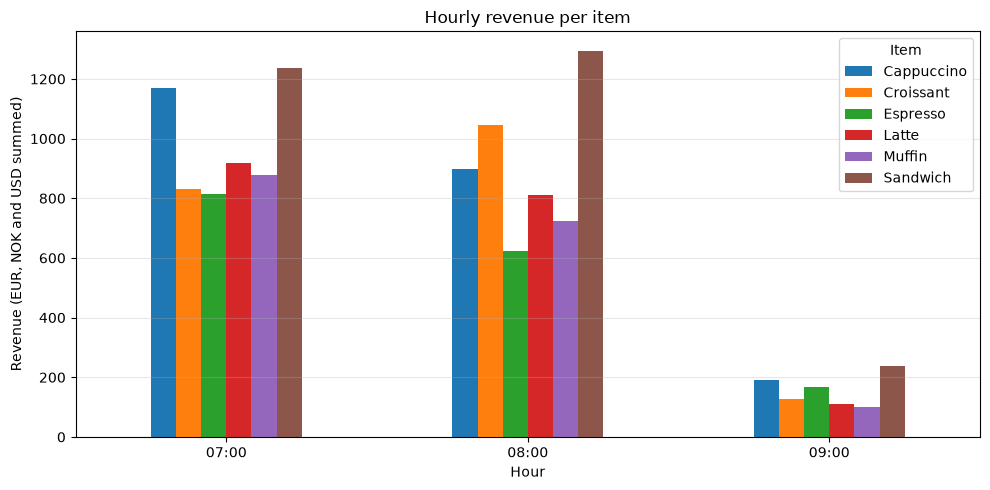

In [17]:
# Revenue per item for each hour. EUR, NOK and USD are summed together, as in the reports
hourly_wide: pd.DataFrame = results["hourly_revenue"]["price"].unstack(level="item")
hourly_wide.index = hourly_wide.index.strftime("%H:%M")

ax = hourly_wide.plot(kind="bar", figsize=(10, 5), rot=0)
ax.set_title("Hourly revenue per item")
ax.set_xlabel("Hour")
ax.set_ylabel("Revenue (EUR, NOK and USD summed)")
ax.legend(title="Item")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

---

### Results and discussion of Task 5

The workflow found the 9 log files and parsed 720 valid transactions, 80 from each register. No transactions were removed by the active register filter, as expected from Task 2.

`remove_outliers` replaced all 20 glitch prices of `999.00` with the median of the valid prices (`3.93`), and no prices of 999.00 or more are left. After the NOK correction, the NOK prices are between `25.20` and `79.60`, while the EUR and USD prices are between about `2.50` and `8.00`, so all three currencies now have realistic prices.

Sandwich has the highest `SUCCESS` revenue and Latte the lowest. Cappuccino has the highest refund ratio (`0.35`) and Latte the lowest (`0.20`). The plot shows that almost all the revenue is from 07:00 and 08:00. The 09:00 bars are low because the logs end at 09:20, so only 56 transactions fall in that hour.

The revenue is still summed across EUR, NOK and USD without converting, since the assignment does not ask for it. After the NOK correction, a NOK transaction counts about 10 times more than a EUR or USD transaction, so the totals are not real amounts of money, and the differences between items partly depend on how many of their transactions were in NOK.

---

# Use of Generative AI

### Task 1

**Idea searching**

* I need an idea for how find the encoding of a file. ChatGPT gave me a list of ways to do it and chardet seemed the easiest

**Structure**

* I couldn't figure out how the structuring of the `re` pattern worked so ChatGPT helped me structure it.

---


### Task 2 

**Questions about the code**
* I asked what each part of the two functions does. Claude explained how `find_log_files` converts the input to a `Path`, uses `iterdir()` to look at one folder at a time, and calls itself on subfolders, and how `find_active_registers` checks each dictionary for `"active": True` and calls itself on every value in dictionaries and lists.
* I asked what was meant by the *base case* in `find_active_registers`. It is when the input is a single value (string, number, bool or `None`), so there is nothing more to search and an empty set is returned. This is what stops the recursion.
* After my first version of `find_log_files` only found one file, I asked where `return sorted(found)` should be placed. It had been indented inside the `for` loop, so the function returned after the first item. It must line up with the loop so the whole folder is searched first.
* I asked why the docstrings were so long, and learned the difference between NumPy-style and Google-style docstrings. We kept NumPy style, with `Parameters` and `Returns` sections.
* I asked what `DATA_DIR` was and where it came from. It is a constant defined in the Setup cell, a relative path to the `d2_data/` folder, written in capitals by convention.

**Questions about the structure**
* How a notebook with many cells is run, and whether the imports at the top are available in the cells below. Variables and functions stay in memory after a cell has run, so the Setup cell only needs to run once, first.
* Why each import is needed and which task uses it, which I wrote as a comment next to each import.
* Why the data path had to match our generator, which saves to `d2_data/` instead of `data/`.

**Errors and corrections**
Claude helped me find errors in my notebook: `extedn` instead of `extend`, `return` indented inside the loop, and `node-values()` instead of `node.values()`, as well as spelling mistakes in the docstrings and markdown.

**What I did myself**
I put together the notebook, adapted the paths and text to our project, fixed the errors and ran the code on our generated data to check that it found all 9 log files and the active registers `{'POS_01', 'POS_02', 'POS_03'}`.

---

### Task 3

**Questions about the code**
* I asked how to get started with `remove_outliers`. Claude split the function into six steps: convert the input to an array, calculate the mean and standard deviation, make a boolean mask of the outliers, take the median of the valid prices, replace the outliers, and return the array.
* I asked how to convert the input to a 1D array. Claude explained `np.array(prices, dtype=float).flatten()`, and that `np.array` and `.flatten()` both make a copy, so the original input is not changed. `np.asarray` and `.ravel()` do not always make a copy.
* I asked what a boolean mask is. It is an array of `True`/`False` values made by a comparison, such as `np.abs(arr - mu) > 3 * sigma`. It can be used to select values (`arr[~mask]`) or replace them (`arr[mask] = median`) without a loop, which is what makes the function vectorised.

**Testing and discussion**
* Claude explained that the 3σ rule cannot detect a single outlier among 10 or fewer values, since one value can be at most $(n-1)/\sqrt{n}$ standard deviations from the mean. Our test therefore uses 13 prices.
* Claude suggested the test cell, with values where the result is easy to check by hand: `999.0` should become `4.25`, and the refund ratios should be `[0.2, 0.25, 0.0]`. It also reminded me to run the Setup cell and the function cells before the test cell.

**Errors and corrections**
Claude reviewed both functions and confirmed that they were correct. It suggested renaming the variable `formula` to `outliers`, since it holds the boolean mask and not the formula. It also suggested a docstring that describes the 3σ rule instead of only referring to "the formula described".

**What I did myself**
I wrote `remove_outliers` and `compute_refund_ratio` myself, following the steps Claude explained, and made the corrections above. I added the test cell and the Results and discussion text to the notebook, and ran the tests to check that the results matched.

---

### Task 4

**Questions about the code**
* Before we started, Claude looked at our Task 1 code and pointed out two things that affect Task 4. The parser returns `price` as text, so summing would join the strings instead of adding the numbers. And the Windows path `d2_data\2026` finds no files on a Mac.
* I asked how to get started with `build_dataframe`. Claude split it into steps: create the DataFrame with `pd.DataFrame()`, convert `timestamp` with `pd.to_datetime()`, convert `price` with `.astype(float)`, then set the index and sort it. I learned that `set_index()` and `sort_index()` return a new DataFrame, so the result must be assigned back.
* I asked how to calculate in 1-hour windows. Claude explained `df.groupby("item")["price"].resample("1h").sum()`. `resample` puts the rows of each item into 1-hour windows labelled by their start time, and hours without transactions get the value 0.
* I asked how to do `refund_ratios`. Claude explained how `pd.crosstab()` counts the transactions for each item and status, how `reindex(..., fill_value=0)` adds a missing status column with zeros, and how `.to_numpy()` turns the columns into arrays for `compute_refund_ratio` from Task 3.

**Testing and discussion**
* The Task 1 parser is not in the delivery notebook yet, so Claude suggested testing on a small list of hand-made transactions instead, and wrote the test cell. The rows are not in time order and the prices are text, to check that `build_dataframe` handles both. Claude ran the test in a separate script before giving it to me.
* Claude drafted the Results and discussion text, and I asked for a much shorter version.

**Errors and corrections**
Claude reviewed `refund_ratios` and confirmed it was correct, and suggested a clearer comment and docstring. When I asked Claude to check the notebook, it ran all four functions on the 720 generated transactions in a separate script, without changing the notebook. It found that the function name `hourely_sales` did not match `hourly_revenue` in the markdown, that three docstrings were still placeholders, and that the test cell was empty. It also pointed out that the `999.00` glitches dominate the totals in the raw data, and that the `numpy` and `pandas` imports should be removed when the code is moved to the delivery notebook.

**What I did myself**
I wrote all four functions myself, following the steps Claude explained. I wrote `status_pivot` without asking Claude. I renamed `hourely_sales` to `hourly_revenue`, wrote the docstrings, and ran the test cell to check that the results matched. I also added a sentence to the discussion explaining why `refund_ratios` only uses `SUCCESS` and `REFUND`.

---

### Task 5

**Questions about the code**
* I asked Claude to confirm that the workflow does what the assignment asks for, using our functions from Task 1-4 and the data from `generate_data_for_d2.py`. Claude went through the seven steps and showed which of our functions is used in each step. Only the NOK correction (step 5) is done directly with pandas, since the assignment does not ask for a separate function.

**Code written by Claude**
* Claude wrote `run_workflow()`, which calls our functions in the same order as the steps in the assignment and saves the four output files in `output/`, together with the markdown cell that describes it. `hourly_revenue.json` is saved as a dictionary of the form `{item: {hour: revenue}}`, since JSON keys have to be strings.
* Claude also wrote the cell that runs the workflow and prints checks of the results, the bar plot of hourly revenue per item, and a draft of the Results and discussion text.

**Errors and corrections**
* Before Task 5, Claude helped me with a merge conflict in the imports cell when merging `task-1` into `main`. The two branches had written the imports differently, and the rest of the notebook uses `pathlib.Path` and `chardet`, so the cell needed both `import pathlib` and `import chardet as cd`.
* When the notebook failed after the merge, Claude found that `chardet` was not installed in our `.venv`. The imports cell stopped there, so `DATA_DIR`, `np` and `pd` were never defined in the cells below.
* Claude removed a `print(line)` in `log_parser` that printed every log line, which would have printed about 800 lines in Task 5. It also did what the note in the Setup cell said: it changed the comments for `DATA_DIR` and `CONFIG_FILE` to "(Task 2 and 5)", removed the note, and added `OUTPUT_DIR`.

**What I did myself**
I resolved the merge conflict in GitHub myself, using the imports Claude suggested, and installed `chardet` in the virtual environment. I asked Claude to check the workflow against the requirements in the assignment.

---